# JAX Extension · Graph Neural Network for Seismic Location — Lab 3 in JAX

**LETMA 2026 Summer School · optional extension** — the same lab as Lab 3
(`lab_gnn_student.ipynb`), reimplemented in **JAX + Equinox + Optax** instead of
PyTorch Geometric. The events, the graph construction (k-NN, $k=6$), the hypotheses
(H1–H7 of Lab 3 §1), the model and every experiment are identical — the data is shipped as
`data/seismic_jax.npz`, generated once with the very same seeds as Lab 3.

> **How JAX replaces PyG — worth understanding, it is half of the lesson.**
> PyTorch Geometric *concatenates* the nodes of a batch into one big graph and carries a
> `batch` vector saying who belongs to whom — elegant, but a dynamic, ragged structure.
> JAX wants fixed shapes (so that `jax.vmap` and `jax.jit` can work). So we **pad** every
> event to the 30 stations of the network and add a **mask** saying which nodes are real;
> messages through padded slots are multiplied by 0, the pooling divides by the true node
> count. Same math, same invariances — different bookkeeping. On real, large graphs people
> do the same trick, or use libraries like `jax-dlrs`; the padded+masked pattern below IS
> the transferable recipe.

**Authors:** E. Noëlé¹²³⁴, Gatti⁵, Lehmann⁵, Millet⁵, Clouteau³

**Affiliations:** ¹ AMIAD — ² CEA — ³ LMPS — ⁴ Centre Borelli — ⁵ CEA/DAM

## §0 · Setup — run me first

In [1]:
# Portable setup: runs unchanged on the Hedy cluster or on a laptop. Run this cell first.
import os, sys, math, time
from pathlib import Path
project_root = next((p for p in [Path(os.environ.get('HEDY_PROJECT_ROOT', Path.cwd())),
                                  Path.cwd(), *Path.cwd().parents]
                     if (p / 'data' / 'seismic_jax.npz').is_file()), None)
if project_root is None:
    raise RuntimeError('data/seismic_jax.npz not found: open this notebook inside the '
                       'tutorial project directory (and run scripts/make_seismic_npz.py once).')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', os.environ.get('LAB_PLOT_MODE', 'inline').strip().lower())

import numpy as np
import jax
import jax.numpy as jnp
import equinox as eqx
import optax
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.collections import LineCollection
from IPython.display import HTML, display

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 12,
                     'axes.labelsize': 11, 'legend.fontsize': 10})
HEDY_SESSION = None
try:
    from hedy_euporie.profiler import begin_session
    HEDY_SESSION = begin_session('jax_gnn_solution', backend='jax')
except Exception:
    print('Hedy session profiling not available here (local/laptop run): continuing without it.')

def show_anim(fig, func, frames, interval=200, blit=False):
    """Inline JavaScript animation: works in Jupyter, JupyterLab and Euporie."""
    ani = animation.FuncAnimation(fig, func, frames=frames, interval=interval, blit=blit)
    plt.close(fig)
    display(HTML(ani.to_jshtml()))

print(f'Python {sys.version.split()[0]} | JAX {jax.__version__} | devices {jax.devices()}')
print(f'backend: {jax.default_backend()} — this lab runs fine on CPU')

Interactive session: jax_gnn_solution | profiling on


Python 3.12.4 | JAX 0.12.0.1 | devices [CudaDevice(id=0)]
backend: gpu — this lab runs fine on CPU


## §1 · From a sensor network to a graph — same task, same hypotheses as Lab 3

An earthquake occurs somewhere in a 100×100 km region; a network of 30 surface stations picks
the P arrival (and, 70% of the time, the S arrival) with noise; each event is seen by a random
subset of stations (0–30% down, at least 6 remain). From those heterogeneous, unordered
observations we want the **hypocentre** $(x, y, z)$. No grid exists — only points and distances:
the native habitat of a graph. $G = (V, E)$: **nodes** = the stations that recorded the event,
**edges** $j \to i$ when $j$ is among the 6 nearest neighbours of $i$ (in $O(nk)$, not $O(n^2)$ —
and distant information must be *routed* through intermediate stations, like waves are).

**Node features (5 numbers, all relative — H6):** position relative to the reference station
(first P arrival), in units of 20 km; P and S arrival times relative to the first P arrival,
in units of 10 s; S-pick indicator. **Target:** hypocentre relative to the reference station,
depth relative to 15 km, all over 20 km — one scale on the three axes (H7).

**Every hypothesis (unchanged from Lab 3):** **H1** Earth model $v_P(z) = 5.5 + 0.03\,z$ km/s,
fixed $v_P/v_S$; **H2** pick noise $\sigma_P = 0.05$ s, $\sigma_S = 0.10$ s, S picked 70% of
the time; **H3** each event loses 0–30% of stations (the node *set* changes per event);
**H4** epicentres and depths i.i.d. uniform, splits by event index; **H5** k-NN with $k = 6$
connects the observations well enough; **H6** translation/origin-time invariance, baked into
relative features; **H7** training loss MSE on the normalized target, reported errors in km.

train: 5139 events x mean 25.7 stations (mask shape (200, 30): every event PADDED to 30 nodes)
val: 1031 events x mean 25.8 stations (mask shape (40, 30): every event PADDED to 30 nodes)


test: 1291 events x mean 25.8 stations (mask shape (50, 30): every event PADDED to 30 nodes)
demo event: 19 stations, hypocentre (km) = [30.4 56.   1.8]
node features (first 6):  dx/20km  dy/20km  dP/10s  dS/10s  S-picked
   +2.579  -0.362  +0.514  +1.049  +1.000
   +3.602  -0.435  +0.876  +1.692  +1.000
   +2.499  -0.752  +0.501  +1.028  +1.000
   +2.700  -1.231  +0.638  +1.260  +1.000
   +3.742  -2.078  +1.094  -0.000  +0.000
   +2.825  -2.493  +0.926  +1.774  +1.000


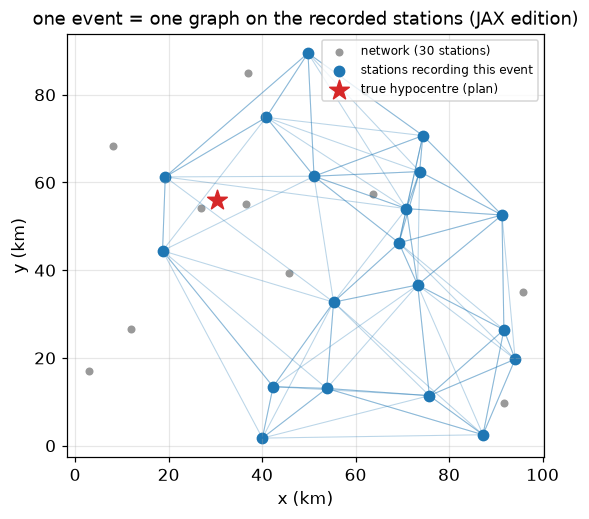

In [2]:
# ---- load the SAME events as Lab 3 (same seeds), shipped as plain arrays ----
DATA = np.load(project_root / 'data' / 'seismic_jax.npz')
NETWORK = DATA['network']                    # (30, 2) station positions (km)
N_MAX, K_NB = 30, 6

def load_split(split):
    d = {k.replace(split + '_', ''): jnp.asarray(DATA[k]) for k in DATA.files
         if k.startswith(split + '_')}
    # edge validity: both endpoints real AND slot < effective k (events with < 7 stations
    # have fewer than 6 neighbours each). Per-event gather (an index (n,30,6) on axis 1 of
    # an (n,30) array would otherwise add a spurious axis).
    b = jnp.arange(len(d['mask']))[:, None, None]
    d['emask'] = (d['mask'][b, d['esrc']] * d['mask'][b, d['edst']]
                  * (jnp.arange(K_NB)[None, None, :] < d['k'][:, None, None]))
    return d

TR, VA, TE = load_split('train'), load_split('val'), load_split('test')
for nm, sp in [('train', TR), ('val', VA), ('test', TE)]:
    print(f"{nm}: {int(sp['mask'].sum())} events x mean {float(sp['n'].mean()):.1f} stations "
          f"(mask shape {sp['mask'].shape}: every event PADDED to 30 nodes)")
Xtr, Mtr, Ptr, EStr, EDtr, EMtr, Ytr = (TR['x'], TR['mask'], TR['pos'], TR['esrc'],
                                        TR['edst'], TR['emask'], TR['y'])
Xva, Mva, Pva, ESva, EDva, EMva, Yva = (VA['x'], VA['mask'], VA['pos'], VA['esrc'],
                                        VA['edst'], VA['emask'], VA['y'])

# ---- one event, one graph: the demo event of the whole notebook ----
i_demo = 0
n_demo = int(np.asarray(DATA['test_n'][i_demo]))
seen = np.asarray(DATA['test_sids'][i_demo])[:n_demo]       # which stations recorded it
pos_demo = np.asarray(DATA['test_pos'][i_demo])[:n_demo]    # relative positions /20km
feat_demo = np.asarray(DATA['test_x'][i_demo])[:n_demo]
hypo_demo = np.asarray(DATA['test_hypo'][i_demo])
print(f'demo event: {n_demo} stations, hypocentre (km) = {hypo_demo.round(1)}')
print('node features (first 6):  dx/20km  dy/20km  dP/10s  dS/10s  S-picked')
for row in feat_demo[:6]:
    print('  ', '  '.join(f'{v:+.3f}' for v in row))

fig, ax = plt.subplots(figsize=(5.6, 5))
ax.scatter(NETWORK[:, 0], NETWORK[:, 1], s=18, c='0.6', label='network (30 stations)')
ax.scatter(NETWORK[seen, 0], NETWORK[seen, 1], s=45, c='C0', label='stations recording this event')
ax.scatter(*hypo_demo[:2], marker='*', s=180, c='C3', label='true hypocentre (plan)')
for i in range(n_demo):                                     # edges, recomputed from pos
    d = np.linalg.norm(pos_demo[:, None] - pos_demo[None], axis=-1)
    d[i, i] = np.inf
    for j in np.argsort(d[i])[:K_NB]:
        ax.plot([NETWORK[seen[i], 0], NETWORK[seen[j], 0]],
                [NETWORK[seen[i], 1], NETWORK[seen[j], 1]], color='C0', alpha=0.3, lw=0.7)
ax.set_xlabel('x (km)'); ax.set_ylabel('y (km)'); ax.legend(fontsize=8, loc='upper right')
ax.set_title('one event = one graph on the recorded stations (JAX edition)'); ax.grid(alpha=0.3)
plt.show()

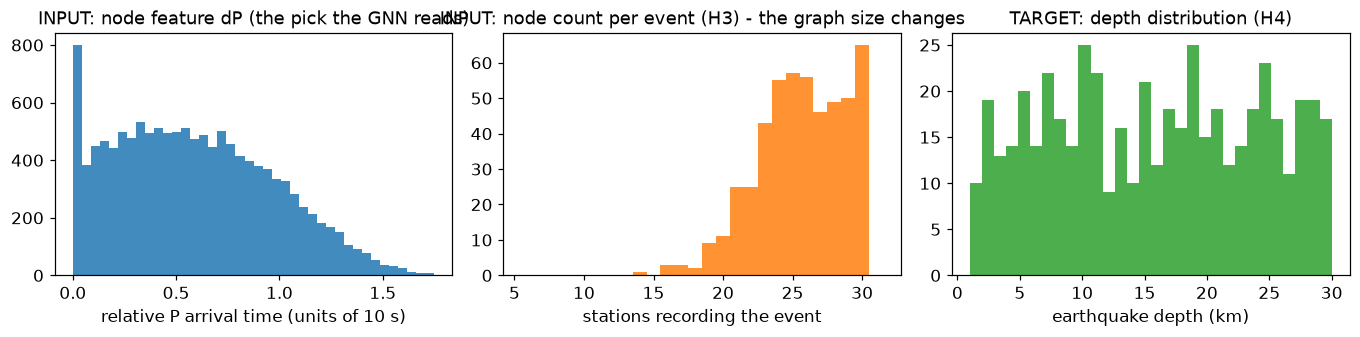

12819 station-event pairs | H3 in numbers: node counts vary from 14 to 30 — the padding + masks of the setup cell handle this


In [3]:
# ---- the statistical distributions of the INPUTS and the TARGET (know your data!) ----
ST = {k.replace('stats_', ''): DATA[k] for k in DATA.files if k.startswith('stats_')}
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.2))
ax[0].hist(ST['x'][:, :, 2][ST['mask'] > 0], bins=40, color='C0', alpha=0.85)
ax[0].set_xlabel('relative P arrival time (units of 10 s)')
ax[0].set_title('INPUT: node feature dP (the pick the GNN reads)')
ax[1].hist(ST['n'], bins=np.arange(5.5, 32, 1), color='C1', alpha=0.85)
ax[1].set_xlabel('stations recording the event')
ax[1].set_title('INPUT: node count per event (H3) - the graph size changes')
ax[2].hist(ST['hypo'][:, 2], bins=30, color='C2', alpha=0.85)
ax[2].set_xlabel('earthquake depth (km)')
ax[2].set_title('TARGET: depth distribution (H4)')
plt.tight_layout(); plt.show()
print(f"{int(ST['mask'].sum())} station-event pairs | H3 in numbers: node counts vary from "
      f"{ST['n'].min()} to {ST['n'].max()} — the padding + masks of the setup cell handle this")

In [4]:
# ---- animation 1: how k-NEAREST-NEIGHBOURS builds the graph, node by node ----
dist_mat = np.linalg.norm(pos_demo[:, None, :] - pos_demo[None, :, :], axis=-1)
dist_mat[np.diag_indices_from(dist_mat)] = np.inf
order = np.argsort(dist_mat, axis=1)

fig, ax = plt.subplots(figsize=(6.8, 6.0))
ax.set_xlim(-4, 104); ax.set_ylim(-4, 104); ax.set_xlabel('x (km)'); ax.set_ylabel('y (km)')
ax.grid(alpha=0.3)
ax.scatter(*NETWORK.T, s=16, c='0.85', zorder=1)
feat = feat_demo[:, 2]
sc_seen = ax.scatter(NETWORK[seen, 0], NETWORK[seen, 1], s=55, c=np.zeros(n_demo),
                     cmap='coolwarm', vmin=-0.1, vmax=float(feat.max()), zorder=3)
(active_pt,) = ax.plot([], [], 'o', color='C3', ms=13, zorder=4)
lc_cand = LineCollection([], color='0.6', lw=0.6, alpha=0.4, zorder=2)
lc_select = LineCollection([], color='C3', lw=2.0, zorder=2)
lc_commit = LineCollection([], color='C0', lw=0.9, alpha=0.7, zorder=2)
for lc in (lc_cand, lc_select, lc_commit):
    ax.add_collection(lc)
hy, = ax.plot([], [], marker='*', ms=18, c='k', ls='none', zorder=5)
title = ax.set_title('')

committed = []
def update(f):
    if f < n_demo:
        i = f
        others = [j for j in range(n_demo) if j != i]
        lc_cand.set_segments([[NETWORK[seen[i], :2], NETWORK[seen[j], :2]] for j in others])
        sel = [order[i, s] for s in range(min(K_NB, n_demo - 1))]
        lc_select.set_segments([[NETWORK[seen[i], :2], NETWORK[seen[j], :2]] for j in sel])
        committed.extend([[NETWORK[seen[i], :2], NETWORK[seen[j], :2]] for j in sel])
        lc_commit.set_segments(list(committed))
        active_pt.set_data([NETWORK[seen[i], 0]], [NETWORK[seen[i], 1]])
        title.set_text(f'node {i + 1}/{n_demo}: grey = all candidates, red = its {K_NB} '
                       'nearest -> edges committed (blue)')
    else:
        lc_cand.set_segments([]); lc_select.set_segments([]); active_pt.set_data([], [])
        sc_seen.set_array(feat)
        hy.set_data([hypo_demo[0]], [hypo_demo[1]])
        title.set_text('graph complete: colors = relative P arrival time; star = hypocentre')
show_anim(fig, update, frames=n_demo + 1, interval=420)

## §2 · Message passing, defined precisely — in padded JAX arrays

One layer, the exact equation of Lab 3 §2:

$$m_{ij} = M_\theta\big(h_i,\, h_j,\, p_j - p_i,\, \lVert p_j - p_i \rVert\big), \qquad
a_i = \frac{1}{|\mathcal N(i)|} \sum_{j \in \mathcal N(i)} m_{ij}, \qquad
h_i \leftarrow h_i + U_\theta\big(h_i, a_i\big).$$

Permutation invariance of $a_i$ (sum/mean treat neighbours unordered); locality per layer and
globality by depth ($\ell$ layers $=$ $\ell$-hop neighbourhoods; 30 nodes with $k=6$ mix in
3–4 hops); relative geometry in the message (translation equivariance, H6).

**In JAX the layer is dense arithmetic on padded arrays** — no scatter, no sparse matrix:
all $N \times K$ messages of the batch are computed at once as `(B, N, K, H)` tensors, and
the aggregation (Exercise G1) is a *masked mean over the K axis*. The mask is what makes the
padding invisible to the math.

**Exercise G1 · 5 minutes** — the masked mean-aggregation, two lines.

In [5]:
# ---- the building blocks: MLP, then one message-passing layer (dense, masked) ----
class Dense(eqx.Module):
    """A linear map on the LAST axis, with arbitrary leading (batch/node/edge) axes.
    Same init as torch.nn.Linear: U(-1/sqrt(fan_in), +1/sqrt(fan_in))."""
    weight: jax.Array
    bias: jax.Array
    def __init__(self, key, d_in, d_out):
        k1, k2 = jax.random.split(key)
        lim = 1.0 / math.sqrt(d_in)
        self.weight = lim * (2 * jax.random.uniform(k1, (d_out, d_in)) - 1)
        self.bias = lim * (2 * jax.random.uniform(k2, (d_out,)) - 1)
    def __call__(self, x):                       # (..., d_in) -> (..., d_out)
        return x @ self.weight.T + self.bias

class MLP(eqx.Module):
    layers: list
    def __init__(self, key, d_in, d_hidden, d_out, n_hidden=1):
        keys = jax.random.split(key, n_hidden + 2)
        dims = [d_in] + [d_hidden] * n_hidden + [d_out]
        self.layers = [Dense(keys[i], dims[i], dims[i + 1]) for i in range(len(dims) - 1)]
    def __call__(self, x):                       # acts on the LAST axis, any leading shape
        for i, l in enumerate(self.layers):
            x = l(x)
            if i < len(self.layers) - 1:
                x = jax.nn.gelu(x)
        return x

class MessageLayer(eqx.Module):
    """h_i <- h_i + U(h_i, masked-mean of M(h_i, h_j, geometry)). Identical math to Lab 3."""
    msg: MLP
    upd: MLP
    def __init__(self, key, hidden=64, pos_dim=2):
        k1, k2 = jax.random.split(key)
        self.msg = MLP(k1, 2 * hidden + pos_dim + 1, hidden, hidden)
        self.upd = MLP(k2, 2 * hidden, hidden, hidden)
    def __call__(self, h, pos, esrc, edst, emask):
        b = jnp.arange(h.shape[0])[:, None, None]           # per-event gather (no double batch)
        hi = h[b, edst]                                     # (B, N, K, H) receiver features
        hj = h[b, esrc]                                     # sender features
        rel = pos[b, esrc] - pos[b, edst]                   # (B, N, K, 2) p_j - p_i
        dist = jnp.linalg.norm(rel, axis=-1, keepdims=True)
        m = self.msg(jnp.concatenate([hi, hj, rel, dist], axis=-1))
        a = aggregate(m, emask)                             # YOUR G1 (or the reference)
        return h + self.upd(jnp.concatenate([h, a], axis=-1))

class LocGNNJAX(eqx.Module):
    """encoder -> L layers -> masked mean pool -> decoder. Same as LocGNN (Lab 3)."""
    encoder: MLP
    layers: list
    decoder: MLP
    def __init__(self, key, in_dim=5, hidden=64, n_layers=4, out_dim=3):
        keys = jax.random.split(key, n_layers + 2)
        self.encoder = MLP(keys[0], in_dim, hidden, hidden)
        self.layers = [MessageLayer(keys[1 + i], hidden) for i in range(n_layers)]
        self.decoder = MLP(keys[-1], hidden, hidden, out_dim)
    def pool(self, h, mask):
        return (h * mask[..., None]).sum(1) / jnp.maximum(mask.sum(1)[..., None], 1.0)
    def __call__(self, x, pos, esrc, edst, emask, mask):
        """The reference forward: encode -> L layers -> masked mean pool -> decode."""
        h = self.encoder(x)
        for layer in self.layers:
            h = layer(h, pos, esrc, edst, emask)
        return self.decoder(self.pool(h, mask))

gnn = LocGNNJAX(jax.random.PRNGKey(0))
n_par = sum(jnp.size(l) for l in jax.tree_util.tree_leaves(eqx.filter(gnn, eqx.is_array)))
print(f'LocGNNJAX(hidden=64, 4 layers): {int(n_par):,} parameters — same size class as Lab 3')

LocGNNJAX(hidden=64, 4 layers): 108,995 parameters — same size class as Lab 3


In [6]:
# ---- Exercise G1 (solution): masked mean-aggregation ----
def my_aggregate(m, emask):
    """m: (B, N, K, H) messages, emask: (B, N, K) 0/1 validity -> a: (B, N, H)."""
    a = (m * emask[..., None]).sum(2)                      # sum of the VALID messages only
    cnt = jnp.maximum(emask.sum(2)[..., None], 1.0)        # |N(i)| per node (>=1: no 0/0)
    return a / cnt

In [7]:
# ---- check G1 against the reference (silent fallback keeps the lab on track) ----
def ref_aggregate(m, emask):
    return (m * emask[..., None]).sum(2) / jnp.maximum(emask.sum(2)[..., None], 1.0)

passed_g1 = False
try:
    km = jax.random.PRNGKey(42)
    m_t = jax.random.normal(km, (3, 7, 6, 4))
    e_t = (jax.random.uniform(jax.random.PRNGKey(43), (3, 7, 6)) > 0.3).astype(jnp.float32)
    err = float(jnp.abs(my_aggregate(m_t, e_t) - ref_aggregate(m_t, e_t)).max())
    passed_g1 = err < 1e-5
    print('G1 check:', f'PASS (max diff {err:.2e})' if passed_g1 else f'FAIL (max diff {err:.2e})')
except NotImplementedError:
    print('G1 check: not implemented yet')
except Exception as e:
    print('G1 check: error ->', type(e).__name__, e)
aggregate = my_aggregate if passed_g1 else ref_aggregate
print('active aggregation:', 'YOURS' if passed_g1 else 'reference fallback')

G1 check: PASS (max diff 0.00e+00)
active aggregation: YOURS


In [8]:
# ---- animation 2: information spreading hop by hop (untrained weights, one event) ----
key = jax.random.PRNGKey(3)
ENC = MLP(key, 5, 64, 64)
layers_mp = [MessageLayer(jax.random.PRNGKey(10 + i), 64) for i in range(4)]
xd = jnp.asarray(feat_demo)[None]                          # (1, n, 5)
pd_ = jnp.asarray(pos_demo)[None]
es = jnp.asarray(DATA['test_esrc'][i_demo])[None][:, :n_demo]
ed = jnp.asarray(DATA['test_edst'][i_demo])[None][:, :n_demo]
em = (jnp.ones((1, n_demo, K_NB)) * (jnp.arange(K_NB)[None, None, :]
      < DATA['test_k'][i_demo]))
def spread(x):
    h = ENC(x); states = [h]
    for l in layers_mp:
        h = l(h, pd_, es, ed, em); states.append(h)
    return states
states = spread(xd)
proj = jax.random.normal(jax.random.PRNGKey(4), (64,)); proj = proj / jnp.linalg.norm(proj)
vals = [np.asarray(st[0] @ proj) for st in states]
vmax = max(abs(v).max() for v in vals)
LBL = ['encoder (own features only)'] + [f'after layer {i}' for i in range(1, 5)]

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.set_xlim(-4, 104); ax.set_ylim(-4, 104); ax.grid(alpha=0.3)
ax.set_xlabel('x (km)'); ax.set_ylabel('y (km)')
sc = ax.scatter(NETWORK[seen, 0], NETWORK[seen, 1], c=vals[0], cmap='coolwarm',
                s=70, vmin=-vmax, vmax=vmax)
fig.colorbar(sc, ax=ax, shrink=0.8, label='projected node state (untrained)')
title = ax.set_title(LBL[0])

def update(f):
    sc.set_array(vals[f])
    title.set_text(LBL[f])
show_anim(fig, update, frames=len(vals), interval=650)
print('Watch the palette MIX: by layer 3-4 the whole network shares one picture of the event.')
print('The next section shows what happens when you keep going: too many layers erase the detail.')

Watch the palette MIX: by layer 3-4 the whole network shares one picture of the event.
The next section shows what happens when you keep going: too many layers erase the detail.


## §3 · Oversmoothing: the deep-GNN trap — the Dirichlet energy

**Definition.** Oversmoothing is the convergence of node representations to a common vector as
message-passing depth grows: $h_i^{(\ell)} \to \bar h$ — the readout then sees the same
average whatever the input. Mean-aggregation applies the smoothing operator $P = D^{-1}A$:
$P^\ell$ is a **low-pass filter on the graph** (components along Laplacian eigenvectors with
$\lambda_k \ne 0$ decay geometrically; only the mean survives). We quantify it with the
**Dirichlet energy** $E(h) = \sum_i \lVert h_i - \bar h \rVert^2$ over the real nodes:
oversmoothing is $E \to 0$.

> **Known results** (Li, Han & Wu, AAAI 2018 and follow-ups): for GCN-type layers on
> connected graphs, node features converge to a common vector and the energy decays
> *exponentially* in depth under mild conditions. Our residual update + GELU soften this —
> it decays more slowly, but the mechanism is identical. Residuals delay oversmoothing;
> they do not repeal it.

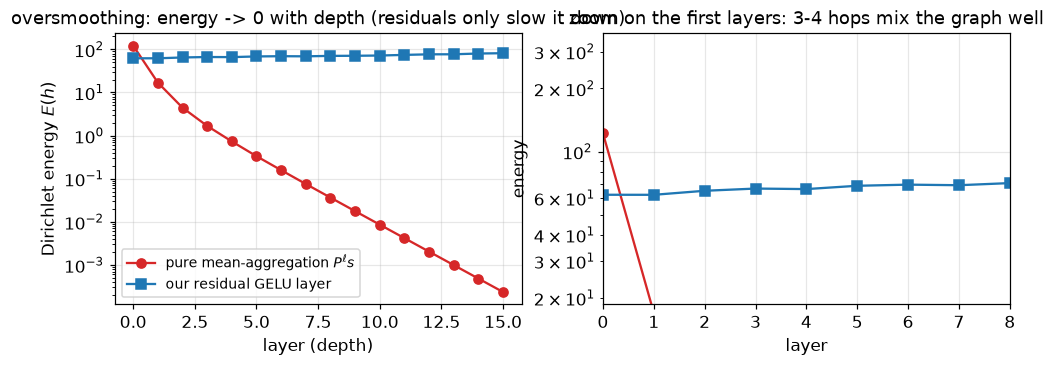

After ~4 layers the mixing is essentially done: deeper layers average what is already an average. Depth beyond the diameter buys nothing and costs information.


In [9]:
# ---- the mechanism isolated: pure repeated averaging vs our residual layer ----
n = n_demo
A = np.zeros((n, n))
kk = int(DATA['test_k'][i_demo])
for i in range(n):
    A[i, np.asarray(DATA['test_esrc'][i_demo][i, :kk])] = 1.0    # i receives from its k
P = A / A.sum(1, keepdims=True)                                   # mean-aggregation operator

rng = np.random.default_rng(5)
signal = rng.normal(size=(n, 8))
E_pure, s = [], signal.copy()
for _ in range(16):
    E_pure.append(((s - s.mean(0))**2).sum())
    s = P @ s

E_res = []
h = np.asarray(ENC(xd)[0])
deep = [MessageLayer(jax.random.PRNGKey(20 + i), 64) for i in range(16)]
states_deep = [h]
for layer in deep:
    h = np.asarray(layer(jnp.asarray(h)[None], pd_, es, ed, em)[0])
    states_deep.append(h)
    E_res.append(((h - h.mean(0))**2).sum())

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
ax[0].semilogy(E_pure, 'o-', color='C3', label=r'pure mean-aggregation $P^\ell s$')
ax[0].semilogy(E_res, 's-', color='C0', label='our residual GELU layer')
ax[0].set_xlabel('layer (depth)'); ax[0].set_ylabel('Dirichlet energy $E(h)$')
ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3)
ax[0].set_title('oversmoothing: energy -> 0 with depth (residuals only slow it down)')
ax[1].plot(E_pure, 'o-', color='C3'); ax[1].plot(E_res, 's-', color='C0')
ax[1].set_yscale('log'); ax[1].set_ylim(max(min(E_res) * 0.3, 1e-3), max(E_pure) * 3)
ax[1].set_xlim(0, 8); ax[1].set_xlabel('layer'); ax[1].set_ylabel('energy')
ax[1].grid(alpha=0.3); ax[1].set_title('zoom on the first layers: 3-4 hops mix the graph well')
plt.show()
print('After ~4 layers the mixing is essentially done: deeper layers average what is already '
      'an average. Depth beyond the diameter buys nothing and costs information.')

In [10]:
# ---- animation 3: oversmoothing made quantitative: node states + the energy curve ----
states_deep_np = [np.asarray(st @ proj) for st in states_deep]
E_deep = [((st - st.mean(0))**2).sum() for st in states_deep]

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={'width_ratios': [1.05, 1]})
sc = ax[0].scatter(NETWORK[seen, 0], NETWORK[seen, 1], c=states_deep_np[0], cmap='coolwarm',
                   s=70, vmin=-vmax, vmax=vmax)
fig.colorbar(sc, ax=ax[0], shrink=0.8, label='projected node state (fixed color scale)')
ax[0].set_xlim(-4, 104); ax[0].set_ylim(-4, 104); ax[0].grid(alpha=0.3)
ax[0].set_xlabel('x (km)'); ax[0].set_ylabel('y (km)')
(lnE,) = ax[1].plot([], [], 'o-', color='C0', lw=1.6)
ax[1].set_yscale('log'); ax[1].set_xlim(0, len(E_deep) - 1)
ax[1].set_ylim(max(min(E_deep) * 0.2, 1e-2), max(E_deep) * 2.5)
ax[1].set_xlabel('depth (message-passing layers)')
ax[1].set_ylabel('Dirichlet energy E(h)  (log)'); ax[1].grid(alpha=0.3)
title = ax[0].set_title('depth 0 (encoder)')

def update(f):
    sc.set_array(states_deep_np[f])
    lnE.set_data(np.arange(f + 1), E_deep[:f + 1])
    title.set_text(f'depth {f}: colors homogenize AND the energy falls: E = {E_deep[f]:.1f}')
show_anim(fig, update, frames=len(states_deep_np), interval=550)
print('Watch the colors collapse: by depth ~10 the stations are interchangeable, and no '
      'locator can work on interchangeable states.')

Watch the colors collapse: by depth ~10 the stations are interchangeable, and no locator can work on interchangeable states.


LocGNNJAX with 1 layer(s): validation error (normalized) = 0.4594


LocGNNJAX with 2 layer(s): validation error (normalized) = 0.4107


LocGNNJAX with 4 layer(s): validation error (normalized) = 0.3962


LocGNNJAX with 8 layer(s): validation error (normalized) = 0.4147


LocGNNJAX with 16 layer(s): validation error (normalized) = 0.3658
depth experiment: 47 s


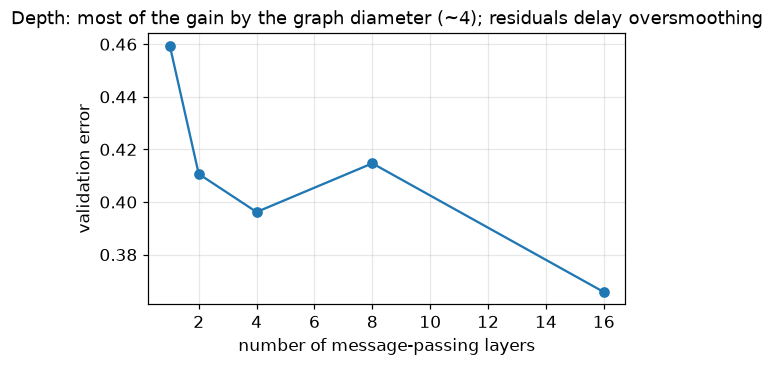

In [11]:
# ---- depth experiment: train 1, 2, 4, 8, 16 layers and compare (same data, short budgets) ----
def val_err(model, sp):
    pred = model(sp['x'], sp['pos'], sp['esrc'], sp['edst'], sp['emask'], sp['mask'])
    return float(jnp.sqrt(((pred - sp['y'])**2).sum(-1)).mean())

def train_short(n_layers, epochs=40, seed=0):
    model = LocGNNJAX(jax.random.PRNGKey(seed), n_layers=n_layers)
    opt = optax.adam(1e-3)
    params, static_ = eqx.partition(model, eqx.is_array)
    opt_state = opt.init(params)

    @eqx.filter_jit
    def step(params, opt_state, xb, pb, sb, db, eb, mb, yb):
        def loss_of(p):
            pred = eqx.combine(p, static_)(xb, pb, sb, db, eb, mb)
            return ((pred - yb)**2).mean()
        loss, grads = jax.value_and_grad(loss_of)(params)
        updates, opt_state = opt.update(grads, opt_state, params=params)
        return optax.apply_updates(params, updates), opt_state, loss

    key_t = jax.random.PRNGKey(seed)
    for ep in range(epochs):
        key_t, sub = jax.random.split(key_t)
        perm = jax.random.permutation(sub, 200)
        for i in range(0, 200, 32):
            idx = perm[i:i + 32]
            params, opt_state, _ = step(params, opt_state, Xtr[idx], Ptr[idx],
                                        EStr[idx], EDtr[idx], EMtr[idx], Mtr[idx], Ytr[idx])
    return val_err(eqx.combine(params, static_), VA)

depths = [1, 2, 4, 8, 16]
val_errs = {}
t0 = time.time()
for d_ in depths:
    val_errs[d_] = train_short(d_)
    print(f'LocGNNJAX with {d_} layer(s): validation error (normalized) = {val_errs[d_]:.4f}')
print(f'depth experiment: {time.time()-t0:.0f} s')

fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.plot(depths, [val_errs[d] for d in depths], 'o-', color='C0')
ax.set_xlabel('number of message-passing layers'); ax.set_ylabel('validation error')
ax.grid(alpha=0.3)
ax.set_title('Depth: most of the gain by the graph diameter (~4); residuals delay oversmoothing')
plt.show()

**Read this experiment** (same reading as Lab 3): our *residual* architecture delays
oversmoothing — most of the gain is already there by ~4 layers (the graph diameter), and on
this budget even 16 layers do not degrade the locator (the seed noise between depths is
comparable to the differences), while the red curve of the energy plot shows the pure
mean-aggregation mechanism collapsing in a handful of layers. When your GNN gets worse as you deepen it, measure the Dirichlet energy per layer
first — it distinguishes oversmoothing (energy $\to 0$) from optimization difficulty
(energy stays high, loss stalls).

## §4 · Train the locator — where is the computation? In the latent space

The pipeline: **encode** each station's 5 physical numbers into a 64-dimensional learned
state → **process** with 4 message-passing layers (states stay per-station, equivariant under
station relabeling) → **pool** into one vector per event by a *masked* mean (invariant) →
**decode** to the 3 normalized hypocentre coordinates. Loss: MSE — with the single 20 km scale
on all three axes (H7), the three error components weigh equally by construction.

**What is being learned, stated rigorously.** The latent space here is a space of *learned
station summaries*: after encoding, the 64 numbers of each node are a learned representation
of "what this station felt" (its position relative to the network, its arrival-time pattern);
each layer widens each node's summary to its graph neighbourhood; the pooled latent vector is
an **event code** — an invariant summary of the whole earthquake — from which the decoder
reads the hypocentre. Nothing in the architecture fixes what the 64 channels mean (they are
learned features, not physics); what the architecture *guarantees* is the invariance: permute
stations → latent states permute → pooled code unchanged → prediction unchanged. That is why
the same trained model handles 26 stations one day and 30 the next.

In [12]:
# ---- Exercise G2 (solution): the full locator, functionally ----
def my_gnn_forward(model, x, pos, esrc, edst, emask, mask):
    """encode -> L message-passing layers -> masked mean pool -> decode. Returns (B, 3)."""
    h = model.encoder(x)                       # (B, N, 5) -> (B, N, H): one state per station
    for layer in model.layers:
        h = layer(h, pos, esrc, edst, emask)   # states stay per-station (equivariant)
    pooled = (h * mask[..., None]).sum(1) / jnp.maximum(mask.sum(1)[..., None], 1.0)
    return model.decoder(pooled)               # (B, 3): the normalized hypocentre

In [13]:
# ---- check G2 against the reference forward (fallback keeps the lab on track) ----
def ref_gnn_forward(model, x, pos, esrc, edst, emask, mask):
    h = model.encoder(x)
    for layer in model.layers:
        h = layer(h, pos, esrc, edst, emask)
    pooled = (h * mask[..., None]).sum(1) / jnp.maximum(mask.sum(1)[..., None], 1.0)
    return model.decoder(pooled)

passed_g2 = False
try:
    b = slice(0, 4)
    p_mine = my_gnn_forward(gnn, Xva[b], Pva[b], ESva[b], EDva[b], EMva[b], Mva[b])
    p_ref = gnn(Xva[b], Pva[b], ESva[b], EDva[b], EMva[b], Mva[b])
    err = float(jnp.abs(p_mine - p_ref).max())
    passed_g2 = err < 1e-5
    print('G2 check:', f'PASS (max diff {err:.2e})' if passed_g2 else f'FAIL (max diff {err:.2e})')
except NotImplementedError:
    print('G2 check: not implemented yet')
except Exception as e:
    print('G2 check: error ->', type(e).__name__, e)
gnn_forward = my_gnn_forward if passed_g2 else ref_gnn_forward
print('active forward pass:', 'YOURS' if passed_g2 else 'reference fallback')

G2 check: PASS (max diff 0.00e+00)
active forward pass: YOURS


training done in 12 s | final validation error 0.3296 (normalized; 1.0 ~ 20 km error)


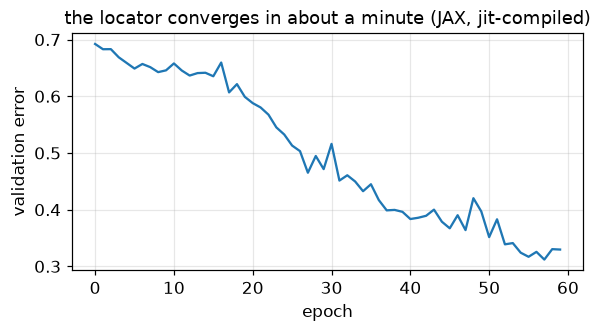

In [14]:
# ---- training (Adam, MSE on normalized targets), with snapshots for the animation ----
locator = LocGNNJAX(jax.random.PRNGKey(0), n_layers=4)
opt = optax.adam(1e-3)
params, static_loc = eqx.partition(locator, eqx.is_array)
opt_state = opt.init(params)

@eqx.filter_jit
def train_step(params, opt_state, xb, pb, sb, db, eb, mb, yb):
    def loss_of(p):
        m = eqx.combine(p, static_loc)
        pred = gnn_forward(m, xb, pb, sb, db, eb, mb)
        return ((pred - yb)**2).mean()
    loss, grads = jax.value_and_grad(loss_of)(params)
    updates, opt_state = opt.update(grads, opt_state, params=params)
    return optax.apply_updates(params, updates), opt_state, loss

EPOCHS = 60
hist, snaps = [], []
key_t = jax.random.PRNGKey(0)
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    key_t, sub = jax.random.split(key_t)
    perm = jax.random.permutation(sub, 200)
    for i in range(0, 200, 32):
        idx = perm[i:i + 32]
        params, opt_state, _ = train_step(params, opt_state, Xtr[idx], Ptr[idx],
                                          EStr[idx], EDtr[idx], EMtr[idx], Mtr[idx], Ytr[idx])
    locator = eqx.combine(params, static_loc)
    hist.append(val_err(locator, VA))
    if ep % 5 == 0 or ep == 1:
        pred_te = gnn_forward(locator, TE['x'][:12], TE['pos'][:12], TE['esrc'][:12],
                              TE['edst'][:12], TE['emask'][:12], TE['mask'][:12])
        snaps.append((ep, np.asarray(pred_te), np.asarray(TE['ref'][:12])))
print(f'training done in {time.time()-t0:.0f} s | final validation error {hist[-1]:.4f} '
      '(normalized; 1.0 ~ 20 km error)')
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(hist, color='C0'); ax.set_xlabel('epoch'); ax.set_ylabel('validation error')
ax.grid(alpha=0.3); ax.set_title('the locator converges in about a minute (JAX, jit-compiled)')
plt.show()

In [15]:
# ---- animation 4: predicted hypocentres converging to the true ones, epoch by epoch ----
def to_km(pred_norm, ref):
    out = pred_norm * 20.0
    return np.concatenate([out[:, :2] + ref, out[:, 2:] + 15.0], axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 5), gridspec_kw={'width_ratios': [3, 1]})
ax[0].scatter(NETWORK[:, 0], NETWORK[:, 1], s=14, c='0.8', zorder=1)
ax[0].set_xlim(-4, 104); ax[0].set_ylim(-4, 104); ax[0].grid(alpha=0.3)
ax[0].set_xlabel('x (km)'); ax[0].set_ylabel('y (km)')
true_xy = np.asarray(DATA['test_hypo'])[:12, :2]
ax[0].scatter(true_xy[:, 0], true_xy[:, 1], marker='*', s=160, c='C0', zorder=3,
              label='true epicentres')
(pred_pts,) = ax[0].plot([], [], 'x', ms=9, c='C3', zorder=4, label='JAX GNN predictions')
ax[0].legend(fontsize=8, loc='upper right')
(loss_ln,) = ax[1].plot([s[0] for s in snaps], [hist[s[0] - 1] for s in snaps], color='0.4')
(dot,) = ax[1].plot([], [], 'o', c='C3')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('val error'); ax[1].grid(alpha=0.3)
title = ax[0].set_title('')

def update(f):
    ep, pred, ref = snaps[f]
    km = to_km(pred, ref)
    pred_pts.set_data(km[:, 0], km[:, 1])
    dot.set_data([ep], [hist[ep - 1]])
    title.set_text(f'epoch {ep}: predicted epicentres (x) vs truth (stars), 12 held-out events')

show_anim(fig, update, frames=len(snaps), interval=420)

## §5 · Evaluate in kilometres — and check that the graph earns its keep

Normalized MSE is for the optimizer; geophysicists report **kilometres** (H7). We convert back
to physical hypocentres, and train the *graph-free* baseline (the same MLP as Lab 3: a fixed
30-station vector with zeros for missing stations) — H3 is precisely what should hurt it.

epicentral error: median 3.08 km | mean 4.08 | 90% 7.71 km
depth error:       median 3.35 km | mean 4.38 | 90% 8.52 km
per-axis medians: x 2.09  y 2.15 z 3.35 km



baseline MLP (fixed 30-station vector): epicentral median 7.04 km | depth median 4.76 km
the graph handles station dropout (H3) gracefully; the fixed-vector MLP pays for it


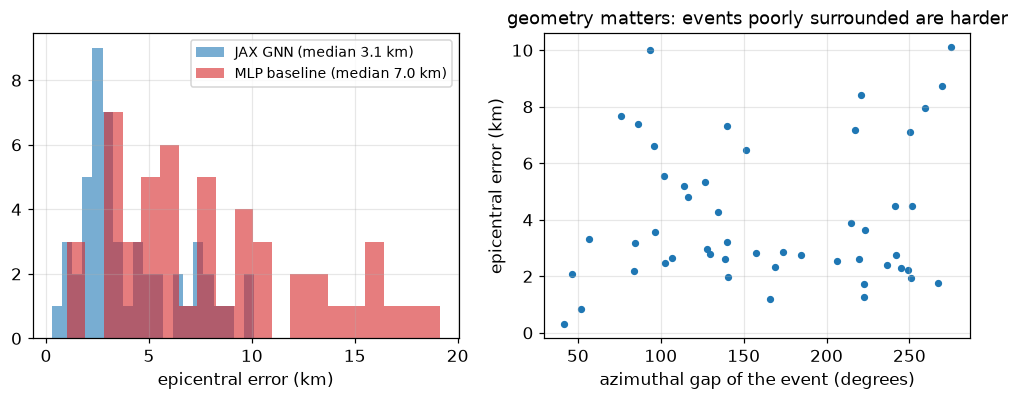

In [16]:
# ---- final evaluation on the 50 untouched test events ----
pred_norm = gnn_forward(locator, TE['x'], TE['pos'], TE['esrc'], TE['edst'],
                       TE['emask'], TE['mask'])
pred_km = to_km(np.asarray(pred_norm), np.asarray(TE['ref']))
hypo_true = np.asarray(DATA['test_hypo'])
errs = np.abs(pred_km - hypo_true)
epi = np.linalg.norm(errs[:, :2], axis=1)
depth = errs[:, 2]
print(f'epicentral error: median {np.median(epi):.2f} km | mean {epi.mean():.2f} '
      f'| 90% {np.quantile(epi, 0.9):.2f} km')
print(f'depth error:       median {np.median(depth):.2f} km | mean {depth.mean():.2f} '
      f'| 90% {np.quantile(depth, 0.9):.2f} km')
print(f'per-axis medians: x {np.median(errs[:, 0]):.2f}  y {np.median(errs[:, 1]):.2f} '
      f'z {np.median(errs[:, 2]):.2f} km')

# ---- the graph-free baseline: the same events as a fixed 30-station vector ----
vec_tr, y_vec_tr = jnp.asarray(DATA['train_vec']), Ytr
vec_te, y_vec_te = jnp.asarray(DATA['test_vec']), TE['y']
class StationMLPJAX(eqx.Module):
    net: MLP
    def __init__(self, key, n_stations=30, in_dim=6, hidden=256, out_dim=3):
        self.net = MLP(key, n_stations * in_dim, hidden, out_dim, n_hidden=2)
    def __call__(self, v): return self.net(v)

mlp_base = StationMLPJAX(jax.random.PRNGKey(0))
opt_b = optax.adam(1e-3)
pb_, sb_ = eqx.partition(mlp_base, eqx.is_array)
os_b = opt_b.init(pb_)

@eqx.filter_jit
def step_b(pb_, os_b, xb, yb):
    def loss_of(p):
        return ((eqx.combine(p, sb_)(xb) - yb)**2).mean()
    loss, g = jax.value_and_grad(loss_of)(pb_)
    up, os_b = opt_b.update(g, os_b, params=pb_)
    return optax.apply_updates(pb_, up), os_b, loss

key_b = jax.random.PRNGKey(0)
for ep in range(60):
    key_b, sub = jax.random.split(key_b)
    perm = jax.random.permutation(sub, 200)
    for i in range(0, 200, 32):
        idx = perm[i:i + 32]
        pb_, os_b, _ = step_b(pb_, os_b, vec_tr[idx], y_vec_tr[idx])
pred_mlp = np.asarray(eqx.combine(pb_, sb_)(vec_te))
pred_mlp_km = to_km(pred_mlp, np.asarray(TE['ref']))
errs_mlp = np.abs(pred_mlp_km - hypo_true)
epi_mlp = np.linalg.norm(errs_mlp[:, :2], axis=1)
print(f'\nbaseline MLP (fixed 30-station vector): epicentral median {np.median(epi_mlp):.2f} km '
      f'| depth median {np.median(errs_mlp[:, 2]):.2f} km')
print('the graph handles station dropout (H3) gracefully; the fixed-vector MLP pays for it')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(epi, bins=20, alpha=0.6, color='C0', label=f'JAX GNN (median {np.median(epi):.1f} km)')
ax[0].hist(epi_mlp, bins=20, alpha=0.6, color='C3',
           label=f'MLP baseline (median {np.median(epi_mlp):.1f} km)')
ax[0].set_xlabel('epicentral error (km)'); ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3)
gaps = np.asarray(DATA['test_gap'])
ax[1].scatter(gaps, epi, s=14, c='C0')
ax[1].set_xlabel('azimuthal gap of the event (degrees)'); ax[1].set_ylabel('epicentral error (km)')
ax[1].grid(alpha=0.3); ax[1].set_title('geometry matters: events poorly surrounded are harder')
plt.show()

**Reading the evaluation** (same as Lab 3): depth errors exceed horizontal ones — a
surface-only array constrains depth through moveout, the weakest part of the signal (a classic
trade-off, inherited from H1's 1-D model); errors grow with the azimuthal gap — the network is
doing *geometry-aware* learning, and its failure modes are the geophysical ones. H1–H4 define a
synthetic world: on real picks you would re-check every hypothesis before trusting a number.

## §6 · Takeaways — JAX, PyG, and using GNNs on *your* problem

- **The graph is a modeling decision, not a file format** — nodes / edges / features /
  invariances (H3, H5, H6) are where your science enters; state them as hypotheses and check them.
- **Framework-specific bookkeeping, framework-independent math**: PyG concatenates ragged
  graphs and scatters; JAX pads and masks. Permutation invariance, locality, oversmoothing —
  all of §2–§3 — live above that layer. Choose your framework for its ecosystem (PyG for
  graphs, JAX for `jit`/`vmap` composability), not for the math.
- **Message passing = local aggregation, depth = range.** Set depth from the graph diameter;
  diagnose degradation with the Dirichlet energy; residuals delay oversmoothing, they do not
  repeal it.
- **Invariance by construction**: relative features + invariant aggregation + pooling = a model
  that works for *any* number of sensors. Here the masked mean-pool is the JAX embodiment of it.

**Checklist for your application** (unchanged from Lab 3): define nodes, edges, features and
your invariances; start shallow ($L \approx$ hops needed); mean-pool for intensive targets,
sum-pool for extensive ones; Adam + MSE on a single well-chosen scale, evaluate in physical
units; always run a graph-free baseline; on regular grids, FNO/FFNO (Labs 1–2) is the cheaper tool.

## References

- T. N. Kipf & M. Welling. *Semi-Supervised Classification with Graph Convolutional Networks.* ICLR 2017.
- J. Gilmer et al. *Neural Message Passing for Quantum Chemistry.* ICML 2017.
- Q. Li, Z. Han & X.-M. Wu. *Deeper Insights into Graph Convolutional Networks.* AAAI 2018.
- P. W. Battaglia et al. *Relational Inductive Biases, Deep Learning, and Graph Networks.* arXiv:1806.01261 (2018).
- K. Xu et al. *How Powerful are Graph Neural Networks?* (jumping knowledge) ICLR 2019.
- J. Bradbury et al. *JAX* (2018); A. Paszke et al. *Equinox* (2022); M. Blondel et al. *Optax* (2021).
- Noëlé, Gatti, Lehmann, Millet, Clouteau. *LETMA 2026 lecture notes* (this school).

In [17]:
if HEDY_SESSION is not None:
    HEDY_SESSION.report()
else:
    print('No Hedy session: nothing to report (laptop run).')

Interactive measurement saved: /home/projects/m26266/letma2026-ml-labs/notebooks/extensions/reports/interactive/jax_gnn_solution_25484_20261029T012646Z.json
Session elapsed (including user idle): 89.819 s
Peak kernel RSS: 2118.22 MiB
